# Observability of full IMU-bias estimation in the CAMLS UWB/IMU EKF

**Case analysed:** every drone carries a full IMU bias, i.e. a 3-axis gyro bias $b_g$ **and** a
3-axis accelerometer bias $b_a$, giving 57 states.

The structure follows `CAMLS_Range_Based_Observability_Analysis.pdf`, but the analysis is done on the
filter as implemented in `src/dynamics.cpp`. The model below is a line-by-line Python port of that file. Its
state derivative and Jacobians agree with the C++ code to machine precision (relative error ≈ 1e-15).

**Results in short** (derived in §4, verified numerically in §6–8)

| | gyro bias $b_g$ | accelerometer bias $b_a$ |
|---|---|---|
| anchor drone (MoCap) | observable, all axes, always | observable, all axes, always |
| other drones, roll/pitch axes | observable, always | horizontal part: **not** observable in hover, weak in flight |
| other drones, yaw axis | observable **unless the cable stays parallel to the specific force** (hover: vertical cable) | vertical part: observable |

The deficit in the accelerometer biases comes from the accelerometer biases alone; estimating the gyro biases does not add it.

## 1. System

| | |
|---|---|
| **States** (57) | payload $[p_L, v_L, \Theta_L, \omega_L]$ (12); per drone $[p_i, v_i, \Theta_i, b_{g,i}, b_{a,i}]$ (15) |
| **Inputs** | per drone the IMU: specific force $f_i$ and body rate $\omega_i$ |
| **Measurements** | anchor drone MoCap $p_0, \Theta_0$ · UWB ranges $r_{01}, r_{02}, r_{12}$ · body-frame cable directions $s_i = R_i^\top q_i$ |

Differences from the PDF model:
* The IMU **drives** the drones instead of being measured:
  $\dot v_i = g + R_i(f_i - b_{a,i})$, $\dot\Theta_i = T(\Theta_i)^{-1}(\omega_i - b_{g,i})$.
  There is no motor model, and the drone body rate is not a state.
* The biases are random-walk states. They only enter the model through $(f_i - b_{a,i})$ and $(\omega_i - b_{g,i})$, so
  $\partial f/\partial b = -\partial f/\partial u$. The gyro bias also reaches the payload through the cable damper when the hook is offset.
* Cable tension is not used as a measurement.

## 2. Setup

In [2]:
import os
# The matrices are small (57 x 57): multi-threaded BLAS only adds overhead (~5x slower). Must be set before numpy.
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(var, "1")

from pathlib import Path

import numpy as np
import yaml
import matplotlib.pyplot as plt
from scipy.linalg import expm, null_space

np.set_printoptions(precision=3, suppress=True)

# repository root = first parent folder that contains the filter parameters
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "params/uwb_imu_ekf.yaml").exists())
DATA_DIR = REPO / "test_data/csv"

with open(REPO / "params/uwb_imu_ekf.yaml") as f:
    PARAMS = yaml.safe_load(f)
DRONE_NAMES = PARAMS["drones"]
print("drones:", DRONE_NAMES, "| anchor:", DRONE_NAMES[PARAMS["filter"]["anchor_drone"]])

drones: ['falcon1', 'falcon2', 'falcon3'] | anchor: falcon1


## 3. Model

### 3.1 Rotations
Conventions as in `dynamics.hpp`: $\Theta = [\text{roll}, \text{pitch}, \text{yaw}]$,
$R = R_z(\psi)R_y(\theta)R_x(\phi)$, body rate $\omega = T(\Theta)\dot\Theta$ (eq. 16).

In [3]:
def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

def euler_to_R(theta):
    return Rz(theta[2]) @ Ry(theta[1]) @ Rx(theta[0])

def R_to_euler(R):
    return np.array([np.arctan2(R[2, 1], R[2, 2]),
                     np.arcsin(np.clip(-R[2, 0], -1.0, 1.0)),
                     np.arctan2(R[1, 0], R[0, 0])])

def T_matrix(theta):
    sr, cr = np.sin(theta[0]), np.cos(theta[0])
    sp, cp = np.sin(theta[1]), np.cos(theta[1])
    return np.array([[1, 0, -sp], [0, cr, sr * cp], [0, -sr, cr * cp]])

def skew(v):
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

def norm(v):
    # sqrt(v.v) instead of np.linalg.norm: no abs(), so complex-step differentiation stays exact (§3.4)
    return np.sqrt(v @ v)

### 3.2 State and input layout

In [4]:
N_DRONES = len(DRONE_NAMES)
DRONE_SIZE = 15                       # p, v, Theta, b_g, b_a
N_STATES = 12 + N_DRONES * DRONE_SIZE
N_INPUTS = 6 * N_DRONES               # per drone: specific force (3), body rate (3)

PAYLOAD_POS, PAYLOAD_VEL, PAYLOAD_ATT, PAYLOAD_RATE = 0, 3, 6, 9
DRONE_BLOCKS = {"pos": 0, "vel": 3, "att": 6, "bg": 9, "ba": 12}

def idx(i, block):
    # Indices of a 3-vector block of drone i
    start = 12 + DRONE_SIZE * i + DRONE_BLOCKS[block]
    return slice(start, start + 3)

def payload_idx(start):
    return slice(start, start + 3)

def acc_input(i):
    return slice(6 * i, 6 * i + 3)

def gyr_input(i):
    return slice(6 * i + 3, 6 * i + 6)

BIAS_STATES = np.r_[tuple(np.r_[idx(i, "bg"), idx(i, "ba")] for i in range(N_DRONES))]
NON_BIAS_STATES = np.setdiff1d(np.arange(N_STATES), BIAS_STATES)
print(f"{N_STATES} states ({len(BIAS_STATES)} bias states), {N_INPUTS} inputs")

57 states (18 bias states), 18 inputs


### 3.3 Dynamics and measurements
`cable()` implements eqs. (4)–(7) and (17), `f()` the process model and `h()` the UWB and cable-direction
measurements, exactly as in `src/dynamics.cpp`.

In [5]:
class CamlsModel:
    def __init__(self, params):
        physics = params["physics"]
        self.g = physics["gravity"]
        self.gravity = np.array([0.0, 0.0, -self.g])
        self.k, self.c = physics["cable_stiffness"], physics["cable_damping"]
        self.allow_slack = physics["allow_slack"]
        self.mL = params["payload"]["mass"]
        self.JL = np.diag(params["payload"]["inertia"])
        geometry = [params["drone_geometry"][name] for name in params["drones"]]
        self.rho = [np.array(d["attach_point_payload"], float) for d in geometry]   # payload frame
        self.hook = [np.array(d["hook_offset"], float) for d in geometry]           # drone body frame
        self.antenna = [np.array(d["uwb_antenna"], float) for d in geometry]        # drone body frame
        self.rest_length = [float(d["cable_length"]) for d in geometry]
        self.drone_mass = [float(d["mass"]) for d in geometry]
        self.anchor = params["filter"]["anchor_drone"]

    def cable(self, x, u, i):
        # Cable i: direction q_i (drone hook -> payload) and tension tau_i
        RL, Ri = euler_to_R(x[payload_idx(PAYLOAD_ATT)]), euler_to_R(x[idx(i, "att")])
        body_rate = u[gyr_input(i)] - x[idx(i, "bg")]
        e = x[payload_idx(PAYLOAD_POS)] + RL @ self.rho[i] - x[idx(i, "pos")] - Ri @ self.hook[i]
        e_dot = (x[payload_idx(PAYLOAD_VEL)] + RL @ np.cross(x[payload_idx(PAYLOAD_RATE)], self.rho[i])
                 - x[idx(i, "vel")] - Ri @ np.cross(body_rate, self.hook[i]))
        length = norm(e)
        q = e / length
        tau = self.k * (length - self.rest_length[i]) + self.c * (e_dot @ q)
        if self.allow_slack and tau.real < 0:
            tau = 0.0 * tau
        return q, tau

    def f(self, x, u):
        # State derivative x' = f(x, u)
        xdot = np.zeros_like(x)
        RL = euler_to_R(x[payload_idx(PAYLOAD_ATT)])
        wL = x[payload_idx(PAYLOAD_RATE)]
        force = self.mL * self.gravity
        torque = -np.cross(wL, self.JL @ wL)
        for i in range(N_DRONES):
            q, tau = self.cable(x, u, i)
            force = force - tau * q
            torque = torque - tau * np.cross(self.rho[i], RL.T @ q)

            theta = x[idx(i, "att")]
            xdot[idx(i, "pos")] = x[idx(i, "vel")]
            xdot[idx(i, "vel")] = self.gravity + euler_to_R(theta) @ (u[acc_input(i)] - x[idx(i, "ba")])
            xdot[idx(i, "att")] = np.linalg.solve(T_matrix(theta), u[gyr_input(i)] - x[idx(i, "bg")])
            # bias rows stay zero: random walk

        xdot[payload_idx(PAYLOAD_POS)] = x[payload_idx(PAYLOAD_VEL)]
        xdot[payload_idx(PAYLOAD_VEL)] = force / self.mL
        xdot[payload_idx(PAYLOAD_ATT)] = np.linalg.solve(T_matrix(x[payload_idx(PAYLOAD_ATT)]), wL)
        xdot[payload_idx(PAYLOAD_RATE)] = np.linalg.solve(self.JL, torque)
        return xdot

    def h(self, x):
        # UWB ranges (0-1, 0-2, 1-2) followed by the body-frame cable directions of all drones
        antenna_pos = [x[idx(i, "pos")] + euler_to_R(x[idx(i, "att")]) @ self.antenna[i] for i in range(N_DRONES)]
        ranges = [norm(antenna_pos[j] - antenna_pos[i]) for i, j in [(0, 1), (0, 2), (1, 2)]]
        no_input = np.zeros(N_INPUTS)  # the cable direction does not depend on the IMU
        directions = [euler_to_R(x[idx(i, "att")]).T @ self.cable(x, no_input, i)[0] for i in range(N_DRONES)]
        return np.concatenate([ranges, *directions])

MODEL = CamlsModel(PARAMS)

### 3.4 Linearisation
The Jacobians are computed by **complex-step differentiation**,
$\partial f/\partial x_k = \operatorname{Im} f(x + i h e_k)/h$ with $h = 10^{-30}$. Unlike finite
differences, nothing is subtracted, so the result is exact to machine precision. This matters for the rank
tests below.

The MoCap rows are written directly, as $H = [I \text{ at } p_0;\ T(\Theta_0) \text{ at } \Theta_0]$ (eq. 40). The filter's
attitude residual is a rotation vector, not a function of $\Theta$ alone.

$C$ has 18 rows: MoCap (6), UWB (3), cable directions (3 × 3).

In [6]:
def complex_step_jacobian(fun, x, step=1e-30):
    x = np.asarray(x, dtype=complex)
    columns = []
    for k in range(x.size):
        dx = np.zeros_like(x)
        dx[k] = 1j * step
        columns.append(fun(x + dx).imag / step)
    return np.column_stack(columns)


def linearize(model, x, u):
    # Returns A = df/dx, B = df/du and C = dh/dx at (x, u)
    x_c, u_c = x.astype(complex), u.astype(complex)
    A = complex_step_jacobian(lambda z: model.f(z, u_c), x)
    B = complex_step_jacobian(lambda v: model.f(x_c, v), u)

    C_mocap = np.zeros((6, N_STATES))
    C_mocap[0:3, idx(model.anchor, "pos")] = np.eye(3)
    C_mocap[3:6, idx(model.anchor, "att")] = T_matrix(x[idx(model.anchor, "att")])
    C = np.vstack([C_mocap, complex_step_jacobian(model.h, x)])
    return A, B, C

Sanity check against central finite differences at a random state:

In [7]:
rng = np.random.default_rng(0)
x_test = rng.normal(scale=0.3, size=N_STATES)
for i in range(N_DRONES):  # keep the cables at a realistic length
    x_test[idx(i, "pos")] += np.array([np.cos(2.1 * i), np.sin(2.1 * i), 1.0]) * 1.1
u_test = rng.normal(scale=0.3, size=N_INPUTS)
u_test[2::6] += PARAMS["physics"]["gravity"]

A, B, C = linearize(MODEL, x_test, u_test)
A_fd = np.column_stack([(MODEL.f(x_test + 1e-6 * e, u_test) - MODEL.f(x_test - 1e-6 * e, u_test)) / 2e-6
                        for e in np.eye(N_STATES)])
print(f"max |A_complex_step - A_finite_diff| / max|A| = {np.abs(A - A_fd).max() / np.abs(A).max():.1e}")
print(f"bias columns equal minus the input columns: "
      f"{all(np.allclose(A[:, idx(i, 'ba')], -B[:, acc_input(i)]) and np.allclose(A[:, idx(i, 'bg')], -B[:, gyr_input(i)]) for i in range(N_DRONES))}")

max |A_complex_step - A_finite_diff| / max|A| = 1.7e-10
bias columns equal minus the input columns: True


## 4. Analytic structure

Write the attitude error of drone $i$ as a **world-frame** rotation vector $\varphi_i = R_i T_i\,\delta\Theta_i$.
Write the measured specific force in the world frame as $a_i = R_i f_i$; this is thrust plus cable force, divided by mass.
To first order:

$$
\delta\dot v_i = -a_i \times \varphi_i - R_i\,\delta b_{a,i},
\qquad
\dot\varphi_i = -R_i\,\delta b_{g,i},
\qquad
\delta s_i = R_i^\top\left(\delta q_i - \varphi_i \times q_i\right),
\qquad
\delta a_i^{\text{ant}} = \delta p_i + \varphi_i \times R_i u_i .
$$

**Anchor drone.** MoCap measures $p_0$ and $\varphi_0$ directly. A constant $\varphi_0$ forces $\delta b_{g,0} = 0$, and
$\ddot p_0 = 0$ then forces $\delta b_{a,0} = 0$. All six biases are observable, with no conditions.

**Other drones** have two attitude references:
1. the **cable direction** sees every attitude error except a rotation about the cable $q_i$;
2. the **accelerometer**, with the position held by UWB and the cable geometry, sees every rotation except one about $a_i$. With
   $b_a$ estimated, a *constant* tilt can hide in the bias ($R_i\delta b_{a,i} = -a_i\times\varphi_i$), so only *changes*
   of $\varphi_i$ are seen: $\tfrac{d}{dt}\delta\dot v_i = a_i \times R_i\,\delta b_{g,i}$.

A gyro-bias error along the world direction $\beta = R_i\,\delta b_{g,i}$ makes $\varphi_i(t) = \varphi_i(0) - \beta t$.
It is invisible to reference 1 iff $\beta \parallel q_i$, and to reference 2 iff $\beta \parallel a_i$. Therefore:

> **The gyro bias of drone $i$ is unobservable iff the cable stays parallel to the specific force,
> $q_i \parallel a_i$. The unobservable direction is that common axis.**

* In hover $a_i = g\,e_z$, so the condition becomes **vertical cables**. The drone is then level, so the axis is body $z$, the yaw bias.
* Roll/pitch gyro biases are **never** unobservable: any horizontal $\beta$ is seen by the accelerometer channel.
* The relevant angle is between the cable and the *specific force*, not between the cable and the thrust as in the PDF. In hover it equals the cable's splay from vertical.
* Any horizontal acceleration tilts $a_i$ away from $q_i$ and restores observability, as in a standard INS.

**Accelerometer biases.** In hover, a tilt combined with a matching horizontal accelerometer bias leaves $\delta\dot v_i = 0$. The drone's attitude
is then held only by its cable (2 axes), and its position only by the geometry. Counting for the two non-anchor drones gives 18 unknowns
($\varphi_i$, $\delta p_i$ for each, plus the payload pose) against 15 constraints: 4 from their cable directions, 2 from the anchor cable,
3 from UWB and 6 from payload force/torque balance. **Expected deficit: 3, independent of the gyro biases.**

Predicted ranks (out of 57): **54** with splayed cables. **52** with vertical cables: the deficit of 3 plus the two yaw gyro biases. Without
lever arms, vertical cables also make the drones' yaw itself unobservable, which leaves 50.

## 5. Equilibria (PDF §7–8)

The cable force vectors $w_i = \tau_i q_i$ must satisfy eq. (19), $\sum w_i = m_L g$ and $\sum c_i \times w_i = 0$.
We pick cables splayed radially outward by a chosen angle and project them onto the nearest solution of (19).
`family_offset` moves the solution along the 3-parameter null space to a generic point of the family. Each drone tilts
into its cable (eq. 23), and its IMU reads $f_i = R_i^\top(0, 0, g)$.

In [8]:
def equilibrium(model, splay_deg, payload_att=(0, 0, 0), drone_yaw=(0, 0, 0), family_offset=None):
    # Static hover of the filter model: returns state x, IMU input u and the cable angles
    RL = euler_to_R(np.array(payload_att, float))
    attach = [RL @ rho for rho in model.rho]                       # c_i, payload at the origin
    A_eq = np.hstack([np.vstack([np.eye(3), skew(c)]) for c in attach])
    b_eq = np.r_[model.mL * model.gravity, 0, 0, 0]

    down = np.array([0.0, 0.0, -1.0])
    if splay_deg == 0:
        # vertical cables: only the three tension magnitudes are unknown
        vertical = np.kron(np.eye(N_DRONES), down[:, None])
        tensions = np.linalg.lstsq(A_eq @ vertical, b_eq, rcond=None)[0]
        w = vertical @ tensions
    else:
        a = np.radians(splay_deg)
        tau0 = model.mL * model.g / (N_DRONES * np.cos(a))
        w_desired = []
        for c in attach:
            outward = np.r_[c[:2] / np.hypot(*c[:2]), 0.0]
            w_desired.append(tau0 * (-np.sin(a) * outward + np.cos(a) * down))
        w_desired = np.concatenate(w_desired)
        if family_offset is not None:
            w_desired = w_desired + null_space(A_eq) @ np.asarray(family_offset)
        w = w_desired + np.linalg.pinv(A_eq) @ (b_eq - A_eq @ w_desired)   # nearest solution of (19)
    assert np.allclose(A_eq @ w, b_eq), "not an equilibrium"

    x, u = np.zeros(N_STATES), np.zeros(N_INPUTS)
    x[payload_idx(PAYLOAD_ATT)] = payload_att
    splay, thrust_cable = [], []
    for i in range(N_DRONES):
        tau = norm(w[3 * i:3 * i + 3])
        q = w[3 * i:3 * i + 3] / tau
        hook_pos = attach[i] - (model.rest_length[i] + tau / model.k) * q

        thrust_axis = model.drone_mass[i] * model.g * np.array([0, 0, 1.0]) - tau * q    # eq. (23)
        z_b = thrust_axis / norm(thrust_axis)
        y_b = np.cross(z_b, [np.cos(drone_yaw[i]), np.sin(drone_yaw[i]), 0.0])
        y_b /= norm(y_b)
        Ri = np.column_stack([np.cross(y_b, z_b), y_b, z_b])

        x[idx(i, "att")] = R_to_euler(Ri)
        x[idx(i, "pos")] = hook_pos - Ri @ model.hook[i]
        u[acc_input(i)] = Ri.T @ np.array([0, 0, model.g])
        splay.append(np.degrees(np.arccos(-q[2])))
        thrust_cable.append(np.degrees(np.arccos(z_b @ -q)))
    return x, u, dict(splay=np.round(splay, 1), thrust_cable=np.round(thrust_cable, 1))


def with_geometry(params, offsets=True, lengths=None):
    # Copy of the parameters with the hook/antenna offsets removed and/or other rest lengths
    params = yaml.safe_load(yaml.safe_dump(params))
    for k, name in enumerate(params["drones"]):
        drone = params["drone_geometry"][name]
        if not offsets:
            drone["hook_offset"] = [0.0, 0.0, 0.0]
            drone["uwb_antenna"] = [0.0, 0.0, 0.0]
        if lengths is not None:
            drone["cable_length"] = lengths[k]
    return CamlsModel(params)

The cases mirror PDF Table 1. "No offsets" means hook and UWB antenna at the drone's centre of mass. "YAML" uses the real geometry
from `uwb_imu_ekf.yaml`, where the antennas sit about 10 cm off-axis.

In [9]:
NO_OFFSETS = with_geometry(PARAMS, offsets=False)
CASES = {
    "E1 vertical, no offsets":        (NO_OFFSETS, dict(splay_deg=0)),
    "E2 20° splay, no offsets":       (NO_OFFSETS, dict(splay_deg=20)),
    "E3 generic point, unequal l":    (with_geometry(PARAMS, offsets=False, lengths=[0.9, 1.0, 1.1]),
                                       dict(splay_deg=20, payload_att=(0.05, -0.04, 0.3), family_offset=[1.5, -1.0, 0.8])),
    "E4 vertical, YAML geometry":     (MODEL, dict(splay_deg=0)),
    "E5 5° splay, YAML geometry":     (MODEL, dict(splay_deg=5)),
    "E6 23° splay, YAML geometry":    (MODEL, dict(splay_deg=23)),
}

LINEARIZATIONS = {}
print(f"{'case':30s} {'splay [deg]':>20s} {'thrust-cable [deg]':>22s} {'max|f(x,u)|':>12s}")
for name, (model, kwargs) in CASES.items():
    x, u, info = equilibrium(model, **kwargs)
    LINEARIZATIONS[name] = (x, *linearize(model, x, u))
    print(f"{name:30s} {str(info['splay']):>20s} {str(info['thrust_cable']):>22s} {np.abs(model.f(x, u)).max():12.1e}")

case                                    splay [deg]     thrust-cable [deg]  max|f(x,u)|
E1 vertical, no offsets                  [0. 0. 0.]             [0. 0. 0.]      4.3e-13
E2 20° splay, no offsets           [22.2 22.2 16.5]       [12.3 12.3  6.7]      3.7e-13
E3 generic point, unequal l        [14.7 34.5 26.2]       [ 8.1 18.1 10.3]      1.4e-13
E4 vertical, YAML geometry               [0. 0. 0.]             [0. 0. 0.]      4.3e-13
E5 5° splay, YAML geometry            [5.6 5.6 4.1]          [3.2 3.2 1.7]      8.1e-13
E6 23° splay, YAML geometry        [25.5 25.5 19.1]       [13.9 13.9  7.7]      4.0e-13


## 6. Rank of the observability matrix

$\mathcal O = [C;\ CA;\ CA^2;\ \dots]$ is built with the two precautions from PDF §10: $A$ is normalised by its 2-norm, and
the basis is re-orthogonalised at every step until the rank stops growing. Bias states are also scaled to their typical size
(0.01 rad/s, 0.1 m/s²) for conditioning; this changes neither the rank nor which directions are observable. Ranks are computed at
two tolerances to show they don't depend on the threshold.

The *bias-free* column removes the 18 bias states, i.e. the current filter without bias estimation, as a reference.

In [10]:
STATE_SCALE = np.ones(N_STATES)
for i in range(N_DRONES):
    STATE_SCALE[idx(i, "bg")] = 0.01
    STATE_SCALE[idx(i, "ba")] = 0.1


def row_basis(M, tol):
    _, s, Vt = np.linalg.svd(M, full_matrices=False)
    return Vt[: int((s > tol * s[0]).sum())]


def observability(A, C, states=None, tol=1e-9):
    # Rank of O for the given state subset, and an orthonormal basis of its null space (scaled coordinates)
    states = np.arange(N_STATES) if states is None else states
    S = np.diag(STATE_SCALE[states])
    A_s = np.linalg.solve(S, A[np.ix_(states, states)] @ S)
    C_s = C[:, states] @ S
    A_s /= np.linalg.norm(A_s, 2)

    basis = row_basis(C_s, tol)
    while True:
        grown = row_basis(np.vstack([basis, basis @ A_s]), tol)
        if len(grown) == len(basis):
            break
        basis = grown
    null = null_space(basis, rcond=tol) if len(basis) < len(states) else np.zeros((len(states), 0))
    return len(basis), null


print(f"{'case':30s} {'bias-free (39)':>16s} {'all biases (57)':>17s}")
for name, (x, A, B, C) in LINEARIZATIONS.items():
    free = [observability(A, C, NON_BIAS_STATES, tol)[0] for tol in (1e-7, 1e-11)]
    full = [observability(A, C, None, tol)[0] for tol in (1e-7, 1e-11)]
    fmt = lambda r: str(r[0]) if r[0] == r[1] else f"{r[0]}/{r[1]} (tol!)"
    print(f"{name:30s} {fmt(free):>16s} {fmt(full):>17s}")

case                             bias-free (39)   all biases (57)
E1 vertical, no offsets                      35                50
E2 20° splay, no offsets                     39                54
E3 generic point, unequal l                  39                54
E4 vertical, YAML geometry                   37                52
E5 5° splay, YAML geometry                   39                54
E6 23° splay, YAML geometry                  39                54


The ranks match the predictions of §4: **54/57 with splayed cables** (a deficit of 3), **52/57 with vertical cables and the real
geometry**, and **50/57 with vertical cables and no lever arms**. Section 7 shows which states make up these deficits.

## 7. Which bias components are observable?

A linear combination $c^\top x$ is observable iff $c$ is orthogonal to the unobservable subspace, the null space of $\mathcal O$.
For each bias axis (body frame), the accelerometer bias along world $z$, and the drone heading (rotation about world $z$), we test whether $\lVert N^\top c\rVert = 0$.

In [21]:
def heading_functional(x, i):
    # e_z^T phi_i: rotation of drone i about the world vertical
    c = np.zeros(N_STATES)
    theta = x[idx(i, "att")]
    c[idx(i, "att")] = (euler_to_R(theta) @ T_matrix(theta)).T @ [0, 0, 1]
    return c


def is_observable(null, c):
    c_scaled = c * STATE_SCALE
    return np.linalg.norm(null.T @ (c_scaled / norm(c_scaled))) < 1e-6


def component_table(x, null):
    rows = []
    for i in range(N_DRONES):
        marks = []
        for block in ("bg", "ba"):
            for axis in range(3):
                c = np.zeros(N_STATES)
                c[idx(i, block).start + axis] = 1.0
                marks.append("✓" if is_observable(null, c) else "✗")
        vertical_acc_bias = np.zeros(N_STATES)
        vertical_acc_bias[idx(i, "ba")] = euler_to_R(x[idx(i, "att")]).T @ [0, 0, 1]
        marks.append("✓" if is_observable(null, vertical_acc_bias) else "✗")
        marks.append("✓" if is_observable(null, heading_functional(x, i)) else "✗")
        rows.append(f"  d{i}{' (anchor)' if i == MODEL.anchor else '         '}   "
                    f"{' '.join(marks[0:3])}       {' '.join(marks[3:6])}         {marks[6]}            {marks[7]}")
    return "\n".join(rows)


print("✓ observable  ✗ unobservable          \n            b_g x y z   b_a x y z   b_a world-z   heading")
for name, (x, A, B, C) in LINEARIZATIONS.items():
    _, null = observability(A, C)
    print(name)
    print(component_table(x, null))

✓ observable  ✗ unobservable          
            b_g x y z   b_a x y z   b_a world-z   heading
E1 vertical, no offsets
  d0 (anchor)   ✓ ✓ ✓       ✓ ✓ ✓         ✓            ✓
  d1            ✓ ✓ ✗       ✗ ✓ ✓         ✓            ✗
  d2            ✓ ✓ ✗       ✗ ✓ ✓         ✓            ✗
E2 20° splay, no offsets
  d0 (anchor)   ✓ ✓ ✓       ✓ ✓ ✓         ✓            ✓
  d1            ✓ ✓ ✓       ✗ ✗ ✗         ✓            ✗
  d2            ✓ ✓ ✓       ✗ ✗ ✗         ✓            ✗
E3 generic point, unequal l
  d0 (anchor)   ✓ ✓ ✓       ✓ ✓ ✓         ✓            ✓
  d1            ✓ ✓ ✓       ✗ ✗ ✗         ✓            ✗
  d2            ✓ ✓ ✓       ✗ ✗ ✗         ✓            ✗
E4 vertical, YAML geometry
  d0 (anchor)   ✓ ✓ ✓       ✓ ✓ ✓         ✓            ✓
  d1            ✓ ✓ ✗       ✗ ✗ ✓         ✓            ✗
  d2            ✓ ✓ ✗       ✗ ✗ ✓         ✓            ✗
E5 5° splay, YAML geometry
  d0 (anchor)   ✓ ✓ ✓       ✓ ✓ ✓         ✓            ✓
  d1            ✓ ✓ ✓       ✗ ✗

* **Anchor drone:** every bias is observable in every case.
* **Gyro bias of drones 1–2:** $x, y$ are always observable. $z$ is observable whenever the cables are splayed (E2, E3, E5, E6, including only 5°),
  and unobservable only with vertical cables (E1, E4). The UWB antenna lever arms don't rescue it (E4).
* **Accelerometer bias of drones 1–2:** part of the horizontal bias is unobservable in every hover case (both horizontal axes once the cables are splayed), which is the deficit of 3 from §4. With a tilted
  drone the body-$z$ axis has a small horizontal component, so $b_{a,z}$ is also marked ✗ in the splayed cases. The bias along world $z$ is observable in all cases.
* The heading is marked ✗ in the splayed cases because it mixes slightly into that accelerometer-bias deficit, not because of the gyro bias.

## 8. How well can the biases be estimated? (covariance analysis)

Rank only says *whether* a state is observable, not *how well*. To quantify this we propagate the EKF covariance (Riccati recursion)
along the true linearisation, with the filter's own `initial_sigma`, `process_noise` and `measurement_noise`. Measurements are fused
once per step, with their noise scaled to the number of samples per step at the recorded rates: MoCap 100 Hz, UWB 40 Hz per pair,
cable direction 300 Hz. A bias σ that stays at its prior means unobservable; σ falling well below the prior means estimable.

In [12]:
RATES_HZ = np.r_[[PARAMS["filter"]["mocap_rate_hz"]] * 6, [40.0] * 3, [300.0] * 9]


def noise_model(params):
    sigma0, q, r = params["initial_sigma"], params["process_noise"], params["measurement_noise"]
    P0, Q_model, imu = np.zeros(N_STATES), np.zeros(N_STATES), np.zeros(N_INPUTS)
    P0[0:12] = np.repeat([sigma0["payload_pos"], sigma0["payload_vel"], sigma0["payload_att"], sigma0["payload_rate"]], 3)
    Q_model[payload_idx(PAYLOAD_VEL)] = q["payload_force"]
    Q_model[payload_idx(PAYLOAD_RATE)] = q["payload_torque"]
    for i in range(N_DRONES):
        P0[idx(i, "pos")], P0[idx(i, "vel")], P0[idx(i, "att")] = sigma0["drone_pos"], sigma0["drone_vel"], sigma0["drone_att"]
        P0[idx(i, "bg")], P0[idx(i, "ba")] = sigma0["gyro_bias"], sigma0["acc_bias"]
        Q_model[idx(i, "bg")], Q_model[idx(i, "ba")] = q["gyro_bias_walk"], q["acc_bias_walk"]
        imu[acc_input(i)], imu[gyr_input(i)] = q["acc"], q["gyro"]
    meas = np.r_[[r["mocap_pos"]] * 3, [r["mocap_att"]] * 3, [r["uwb"]] * 3, [r["cable_dir"]] * 9]
    return np.diag(P0**2), np.diag(Q_model**2), np.diag(imu**2), meas**2


P0, Q_MODEL, SIGMA_IMU, R_MEAS = noise_model(PARAMS)


def discretize(A, B, C, dt):
    return expm(A * dt), (B @ SIGMA_IMU @ B.T + Q_MODEL) * dt, C, np.diag(R_MEAS / (RATES_HZ * dt))


def covariance_analysis(steps, P=P0):
    # Kalman covariance recursion; steps = iterable of (Phi, Qd, C, R). Returns final P and sigma history.
    sigma = []
    for Phi, Qd, C, R in steps:
        P = Phi @ P @ Phi.T + Qd
        K = np.linalg.solve(C @ P @ C.T + R, C @ P).T
        I_KC = np.eye(N_STATES) - K @ C
        P = I_KC @ P @ I_KC.T + K @ R @ K.T      # Joseph form, as in ekf.cpp
        sigma.append(np.sqrt(np.diag(P)))
    return P, np.array(sigma)


def heading_sigma_deg(P, x, i):
    c = heading_functional(x, i)
    return np.degrees(np.sqrt(c @ P @ c))

### 8.1 Hover: dependence on the cable splay
60 s of hover with the real geometry at increasing splay angles. Drone 1 and drone 2 are the non-anchor drones.

In [13]:
DT, HOVER_TIME = 0.02, 60.0
SPLAYS = [0, 1, 2, 5, 10, 20, 30]

sweep = []
for splay in SPLAYS:
    x, u, info = equilibrium(MODEL, splay)
    step = discretize(*linearize(MODEL, x, u), DT)
    P, _ = covariance_analysis([step] * int(HOVER_TIME / DT))
    sd = np.sqrt(np.diag(P))
    sweep.append(dict(splay=info["splay"][1:],
                      bg_z=[sd[idx(i, "bg")][2] for i in (1, 2)],
                      bg_x=[sd[idx(i, "bg")][0] for i in (1, 2)],
                      ba_xy=[sd[idx(i, "ba")][:2].max() for i in (1, 2)],
                      heading=[heading_sigma_deg(P, x, i) for i in (1, 2)]))

print(f"σ after {HOVER_TIME:.0f} s of hover (prior: b_g {PARAMS['initial_sigma']['gyro_bias']} rad/s, "
      f"b_a {PARAMS['initial_sigma']['acc_bias']} m/s²)")
print(f"{'splay d1/d2 [deg]':>18s} {'b_g,z [rad/s]':>18s} {'b_g,x [rad/s]':>18s} {'b_a,xy [m/s²]':>16s} {'heading [deg]':>14s}")
for s in sweep:
    pair = lambda v, f: " / ".join(f.format(e) for e in v)
    print(f"{pair(s['splay'], '{:.1f}'):>18s} {pair(s['bg_z'], '{:.1e}'):>18s} {pair(s['bg_x'], '{:.1e}'):>18s} "
          f"{pair(s['ba_xy'], '{:.3f}'):>16s} {pair(s['heading'], '{:.1f}'):>14s}")

σ after 60 s of hover (prior: b_g 0.01 rad/s, b_a 0.1 m/s²)
 splay d1/d2 [deg]      b_g,z [rad/s]      b_g,x [rad/s]    b_a,xy [m/s²]  heading [deg]
         0.0 / 0.0  9.6e-03 / 9.7e-03  1.4e-03 / 1.4e-03    0.078 / 0.073    33.1 / 33.7
         1.1 / 0.8  4.1e-03 / 4.7e-03  1.4e-03 / 1.4e-03    0.080 / 0.084    13.2 / 15.7
         2.2 / 1.6  3.2e-03 / 4.0e-03  1.4e-03 / 1.4e-03    0.080 / 0.083     9.8 / 12.9
         5.6 / 4.1  2.5e-03 / 3.1e-03  1.4e-03 / 1.4e-03    0.078 / 0.078      6.8 / 9.3
        11.2 / 8.2  2.0e-03 / 2.4e-03  1.4e-03 / 1.4e-03    0.080 / 0.085      4.6 / 6.5
       22.2 / 16.5  1.7e-03 / 1.9e-03  1.4e-03 / 1.4e-03    0.085 / 0.091      3.0 / 4.1
       33.0 / 25.2  1.6e-03 / 1.7e-03  1.4e-03 / 1.4e-03    0.086 / 0.093      2.3 / 3.1


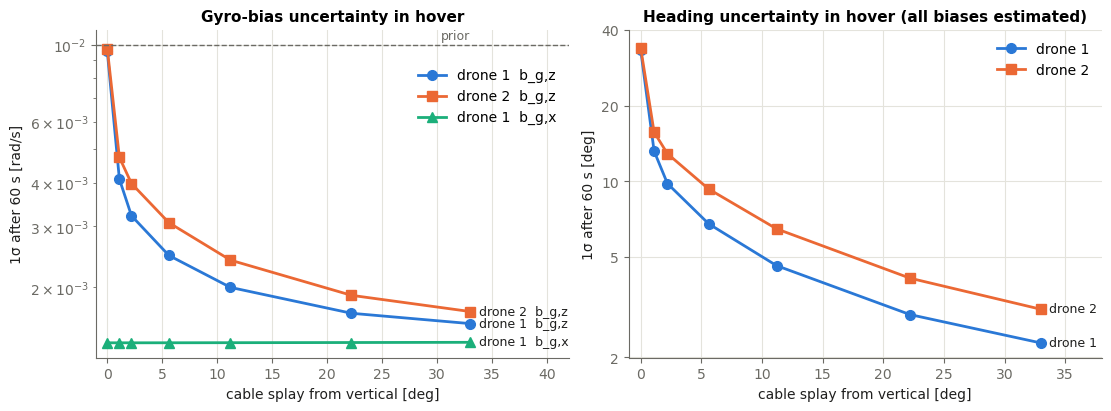

In [14]:
# Plot style: validated categorical slots (blue, orange, aqua), recessive grid, direct labels
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
MARKERS = ["o", "s", "^"]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3dc"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "lines.linewidth": 2, "lines.markersize": 7,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False})


def label_line_end(ax, x, y, text):
    ax.annotate(text, (x[-1], y[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9)


splay_d1 = [s["splay"][0] for s in sweep]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
series = [("drone 1  b_g,z", [s["bg_z"][0] for s in sweep]),
          ("drone 2  b_g,z", [s["bg_z"][1] for s in sweep]),
          ("drone 1  b_g,x", [s["bg_x"][0] for s in sweep])]
for (label, values), color, marker in zip(series, COLORS, MARKERS):
    ax1.plot(splay_d1, values, color=color, marker=marker, label=label)
    label_line_end(ax1, splay_d1, values, label)
ax1.axhline(PARAMS["initial_sigma"]["gyro_bias"], color=MUTED, linestyle="--", linewidth=1)
ax1.annotate("prior", (splay_d1[-1], PARAMS["initial_sigma"]["gyro_bias"]), xytext=(0, 4),
             textcoords="offset points", ha="right", color=MUTED, fontsize=9)
ax1.set(yscale="log", xlabel="cable splay from vertical [deg]", ylabel="1σ after 60 s [rad/s]",
        title="Gyro-bias uncertainty in hover", xlim=(-1, 42))
ax1.legend(loc="upper right", bbox_to_anchor=(1.0, 0.92))

for k, color, marker in zip((0, 1), COLORS, MARKERS):   # drones 1 and 2
    values = [s["heading"][k] for s in sweep]
    ax2.plot(splay_d1, values, color=color, marker=marker, label=f"drone {k + 1}")
    label_line_end(ax2, splay_d1, values, f"drone {k + 1}")
ax2.set(yscale="log", xlabel="cable splay from vertical [deg]", ylabel="1σ after 60 s [deg]",
        title="Heading uncertainty in hover (all biases estimated)", xlim=(-1, 38))
ax2.set_yticks([2, 5, 10, 20, 40], labels=["2", "5", "10", "20", "40"])
ax2.minorticks_off()
ax2.legend(loc="upper right")
plt.show()

With vertical cables the yaw gyro bias stays at its prior. The heading then drifts freely: $0.01\,\text{rad/s} \times 60\,\text{s} \approx 34°$.
A single degree of splay already makes the yaw bias observable. From about 20° it converges almost as fast as the roll/pitch biases,
and the heading stays within a few degrees. The horizontal accelerometer biases stay near their prior (≈0.07–0.09 m/s²) at every splay.

### 8.2 Recorded flights
Ground-truth states and the IMU (averaged over each grid cell) from the datasets in `test_data/csv`, linearised on a 20 Hz grid.
This section is skipped if the data is not present, since `test_data` is not in the repository. It takes about 3 minutes, because every grid point
needs 75 model evaluations for the Jacobians.

In [15]:
FLIGHTS = ["fscale3_hover", "fixed_circle_test1", "fscale7_figure8_test1"]
GRID_HZ = 20.0


def read_csv(path):
    t_ns = np.loadtxt(path, delimiter=",", skiprows=1, usecols=0, dtype=np.int64)
    return t_ns, np.loadtxt(path, delimiter=",", skiprows=1)[:, 1:]


def quat_to_R(q):
    x, y, z, w = q / norm(q)
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
                     [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
                     [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)]])


def load_flight(name, rate_hz=GRID_HZ):
    # Ground-truth states X and IMU inputs U on a uniform grid t [s]
    folder = DATA_DIR / name
    payload = read_csv(folder / "payload.csv")
    odom = [read_csv(folder / f"odom_{n}.csv") for n in DRONE_NAMES]
    imu = [read_csv(folder / f"imu_{n}.csv") for n in DRONE_NAMES]
    streams = [payload, *odom, *imu]
    t_ref = max(t[0] for t, _ in streams)
    seconds = lambda t_ns: (t_ns - t_ref) * 1e-9
    dt = 1.0 / rate_hz
    t = np.arange(dt, seconds(min(s[0][-1] for s in streams)) - dt, dt)

    def pose(stream):  # columns: p(3) q(4: x y z w) v(3) w_body(3)  ->  [p, v, Theta, w_body]
        ts, d = stream
        q = d[:, 3:7].copy()
        q[1:] *= np.cumprod(np.sign(np.sum(q[1:] * q[:-1], axis=1)))[:, None]   # no sign flips
        d = np.column_stack([d[:, 0:3], q, d[:, 7:]])
        cols = np.column_stack([np.interp(t, seconds(ts), d[:, k]) for k in range(d.shape[1])])
        theta = np.array([R_to_euler(quat_to_R(qk)) for qk in cols[:, 3:7]])
        return np.hstack([cols[:, 0:3], cols[:, 7:10], theta, cols[:, 10:13]])

    def imu_average(stream):
        ts, d = stream
        cumulative = np.vstack([np.zeros(6), np.cumsum(d, axis=0)])
        lo, hi = np.searchsorted(seconds(ts), t - dt / 2), np.searchsorted(seconds(ts), t + dt / 2)
        return (cumulative[hi] - cumulative[lo]) / np.maximum(hi - lo, 1)[:, None]

    X, U = np.zeros((len(t), N_STATES)), np.zeros((len(t), N_INPUTS))
    X[:, 0:12] = pose(payload)
    for i in range(N_DRONES):
        X[:, idx(i, "pos").start:idx(i, "att").stop] = pose(odom[i])[:, 0:9]   # the drone rate is an input
        U[:, 6 * i:6 * i + 6] = imu_average(imu[i])
    return t, X, U


def cable_splay_deg(model, x, i):
    q, _ = model.cable(x, np.zeros(N_INPUTS), i)
    return np.degrees(np.arccos(-q[2]))

In [16]:
flight_results = {}
for name in FLIGHTS:
    if not (DATA_DIR / name).exists():
        print(f"skipping {name}: no data in {DATA_DIR}")
        continue
    t, X, U = load_flight(name)
    steps = (discretize(*linearize(MODEL, x, u), 1.0 / GRID_HZ) for x, u in zip(X, U))
    P, sigma = covariance_analysis(steps)
    splay = np.array([[cable_splay_deg(MODEL, x, i) for i in range(N_DRONES)] for x in X[::10]])
    flight_results[name] = dict(t=t, sigma=sigma, P=P, splay=splay)
    print(f"{name}: {t[-1]:.0f} s, mean splay per drone {np.round(splay.mean(axis=0), 1)} deg")

fscale3_hover: 26 s, mean splay per drone [22.8 21.6 15.3] deg
fixed_circle_test1: 98 s, mean splay per drone [30.2 28.9 21.3] deg
fscale7_figure8_test1: 72 s, mean splay per drone [27.2 25.9 19.4] deg


In [17]:
if flight_results:
    print(f"Final 1σ (prior: b_g {PARAMS['initial_sigma']['gyro_bias']} rad/s, b_a {PARAMS['initial_sigma']['acc_bias']} m/s²)")
    print(f"{'flight':24s} {'drone':>6s} {'b_g x, y, z [rad/s]':>28s} {'b_a x, y, z [m/s²]':>24s}")
    for name, res in flight_results.items():
        sd = res["sigma"][-1]
        for i in range(N_DRONES):
            print(f"{name:24s} {'d' + str(i):>6s} {', '.join(f'{v:.1e}' for v in sd[idx(i, 'bg')]):>28s} "
                  f"{', '.join(f'{v:.3f}' for v in sd[idx(i, 'ba')]):>24s}")

Final 1σ (prior: b_g 0.01 rad/s, b_a 0.1 m/s²)
flight                    drone          b_g x, y, z [rad/s]       b_a x, y, z [m/s²]
fscale3_hover                d0    2.0e-03, 2.0e-03, 2.0e-03      0.020, 0.020, 0.020
fscale3_hover                d1    2.1e-03, 2.1e-03, 3.3e-03      0.083, 0.083, 0.023
fscale3_hover                d2    2.1e-03, 2.0e-03, 3.8e-03      0.074, 0.088, 0.022
fixed_circle_test1           d0    1.2e-03, 1.2e-03, 1.2e-03      0.012, 0.012, 0.012
fixed_circle_test1           d1    1.2e-03, 1.2e-03, 1.3e-03      0.055, 0.048, 0.014
fixed_circle_test1           d2    1.2e-03, 1.2e-03, 1.3e-03      0.041, 0.051, 0.013
fscale7_figure8_test1        d0    1.3e-03, 1.3e-03, 1.3e-03      0.013, 0.013, 0.013
fscale7_figure8_test1        d1    1.3e-03, 1.3e-03, 1.5e-03      0.045, 0.045, 0.014
fscale7_figure8_test1        d2    1.3e-03, 1.3e-03, 1.5e-03      0.042, 0.044, 0.013


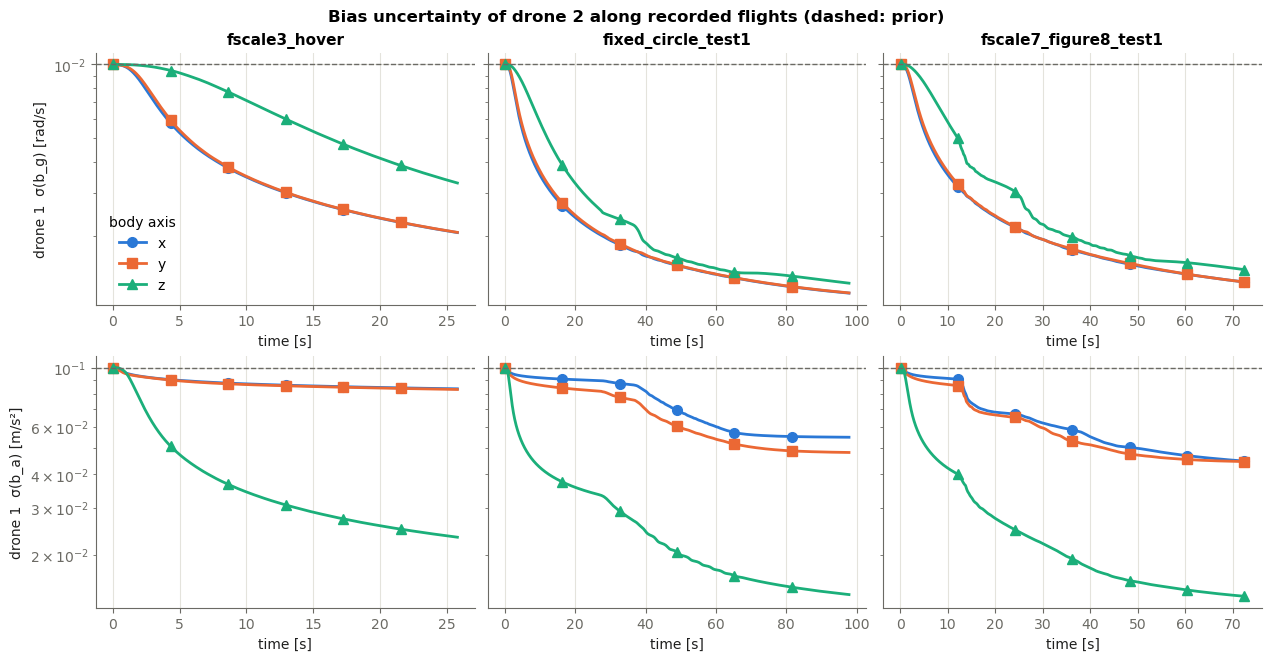

In [18]:
if flight_results:
    drone = 1   # a non-anchor drone
    fig, axes = plt.subplots(2, len(flight_results), figsize=(4.2 * len(flight_results), 6.5),
                             sharey="row", constrained_layout=True, squeeze=False)
    for col, (name, res) in enumerate(flight_results.items()):
        for row, (block, prior, unit) in enumerate([("bg", PARAMS["initial_sigma"]["gyro_bias"], "rad/s"),
                                                    ("ba", PARAMS["initial_sigma"]["acc_bias"], "m/s²")]):
            ax = axes[row, col]
            for axis, (color, marker) in enumerate(zip(COLORS, MARKERS)):
                values = res["sigma"][:, idx(drone, block)][:, axis]
                ax.plot(res["t"], values, color=color, label=f"{'xyz'[axis]}",
                        marker=marker, markevery=max(1, len(values) // 6))
            ax.axhline(prior, color=MUTED, linestyle="--", linewidth=1)
            ax.set(yscale="log", xlabel="time [s]")
            if col == 0:
                ax.set_ylabel(f"drone {drone}  σ({'b_g' if block == 'bg' else 'b_a'}) [{unit}]")
            if row == 0:
                ax.set_title(name)
    axes[0, 0].legend(title="body axis", loc="lower left")
    fig.suptitle(f"Bias uncertainty of drone {drone+1} along recorded flights (dashed: prior)", fontweight="bold")
    plt.show()

In every flight (mean splay 15–30°), all three gyro-bias axes of the non-anchor drones converge, and the yaw axis converges almost as fast as roll and pitch.
The horizontal accelerometer biases converge only partially in flight, which is the weak direction found in §6–7.

## 9. Conditions for observability

With all IMU biases estimated (57 states), the system is locally observable **except** in the directions below.

| Bias | Observable when | Unobservable when |
|---|---|---|
| anchor drone, all axes | always (MoCap pose) | never |
| other drones, gyro roll/pitch | always | never |
| other drones, gyro yaw | the cable is not parallel to the drone's specific force (hover: cable not vertical; or any horizontal acceleration) | the cable stays parallel to the specific force, e.g. vertical cables in hover. The UWB lever arms do not help. |
| other drones, accelerometer horizontal | the drone's attitude/acceleration changes over time (flight); even then only weakly | constant attitude and specific force (hover): tilt and horizontal bias are indistinguishable |
| other drones, accelerometer vertical | always (hover and flight) | – |

**Feasibility.** Full gyro-bias estimation is feasible for the CAMLS flights. All recorded flights have mean splays of 15–30°, and there all gyro axes converge.
To guard against near-vertical cables, de-weight or freeze the $b_{g,z}$ update of a drone whose cable splay is below `diagnostics.splay_vertical_tol` (5°).
The weak part of the bias estimation is the horizontal accelerometer bias of the non-anchor drones, which does not depend on whether the gyro biases are estimated.

*Scope:* local (linearised) observability with Euler angles; taut cables with a valid cable-direction measurement on every drone; the noise levels and
measurement rates of `uwb_imu_ekf.yaml` and the simulated datasets.